# Autonomous Hybrid Notebook for DDoS Detection on CIC-DDoS2019

This notebook is a **standalone, Colab-ready version** of the project. It is designed to run with only:
- this notebook
- the CIC-DDoS2019 CSV files used in the study

It does **not** depend on:
- `ddos_lstm_project.py`
- saved `outputs/*.json` files
- any other local project artifacts

## Scope
This hybrid notebook focuses on a **controlled subset** so that it remains stable, readable, and executable in notebook environments such as Google Colab.

It includes:
- safe chunk-based loading from the dataset files
- data audit and cleaning
- leakage-aware preprocessing
- a multiclass **row-wise benchmark**
- a stricter **group-aware robustness check** using `source_ip`
- a lightweight feature ablation on `inbound`
- comparison between a baseline model and an LSTM

## Target Classes
- `BENIGN`
- `DrDoS_DNS`
- `DrDoS_NTP`
- `DrDoS_NetBIOS`
- `Portmap`

## Important Methodological Note
CIC-DDoS2019 is primarily a **tabular flow dataset**. The LSTM is therefore used through a constructed temporal view of flows rather than a naturally sequential labeling setup.

## Colab Setup

If you run this notebook in Google Colab:
1. mount Google Drive
2. place the dataset folders and this notebook in the same project directory
3. change the working directory to that folder
4. install the Python libraries listed below if needed

The notebook is intentionally configured to use a **controlled subset** so that it executes in a practical amount of time.

In [1]:
# Optional Colab setup cell.
# Uncomment and adapt only when running in Google Colab.

# from google.colab import drive
# drive.mount('/content/drive')

# import os
# PROJECT_DIR = '/content/drive/MyDrive/ddos_project'
# os.chdir(PROJECT_DIR)

# !pip install -q numpy pandas scikit-learn matplotlib seaborn imbalanced-learn torch

In [2]:
# Imports and configuration.

from pathlib import Path
import random
import re
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import torch
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, average_precision_score, classification_report, confusion_matrix, f1_score, roc_auc_score
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, StandardScaler, label_binarize
from torch import nn
from torch.utils.data import DataLoader, Dataset

warnings.filterwarnings('ignore')
plt.style.use('seaborn-v0_8-whitegrid')
pd.set_option('display.max_columns', 120)
pd.set_option('display.width', 180)

SEED = 42
BASE_DIR = Path.cwd()
DATA_FILES = [
    BASE_DIR / '01-12' / 'DrDoS_DNS.csv',
    BASE_DIR / '01-12' / 'DrDoS_NTP.csv',
    BASE_DIR / '01-12' / 'DrDoS_NetBIOS.csv',
    BASE_DIR / '03-11' / 'Portmap.csv',
]
CHUNK_SIZE = 20_000
MAX_CHUNKS_PER_FILE = 5
MAX_ROWS_PER_FILE = 4_000
SEQUENCE_LENGTH = 5
BATCH_SIZE = 256
LSTM_HIDDEN_SIZE = 32
LSTM_DROPOUT = 0.2
LSTM_LEARNING_RATE = 1e-3
LSTM_MAX_EPOCHS = 6
LSTM_PATIENCE = 2
GROUP_TEST_SIZE = 0.2


def set_seed(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)


set_seed(SEED)
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('Base directory:', BASE_DIR)
print('Device:', DEVICE)
print('Controlled subset:', MAX_ROWS_PER_FILE, 'rows per file from up to', MAX_CHUNKS_PER_FILE, 'chunks')

Base directory: C:\Users\nourg\Downloads\archive (1)
Device: cpu
Controlled subset: 4000 rows per file from up to 5 chunks


## Helper Functions

All project logic used below is embedded directly in this notebook so that it stays portable and independent from external project scripts.

In [3]:
def sanitize_name(name: str) -> str:
    name = str(name).strip().lower()
    name = re.sub(r'[^a-z0-9]+', '_', name)
    name = re.sub(r'_+', '_', name).strip('_')
    return name or 'unnamed'


def standardize_columns(columns):
    seen = {}
    cleaned = []
    for column in columns:
        base = sanitize_name(column)
        count = seen.get(base, 0)
        new_name = f'{base}_{count}' if count else base
        seen[base] = count + 1
        cleaned.append(new_name)
    return cleaned


def infer_target_column(columns):
    for candidate in ['label', 'target', 'class', 'attack', 'category']:
        for column in columns:
            if sanitize_name(column) == candidate:
                return column
    raise ValueError('Could not infer the target column automatically.')


def find_duplicate_columns(df):
    duplicate_columns = []
    signatures = {}
    for column in df.columns:
        signature = tuple(df[column].astype(str).fillna('<NA>').head(3000).tolist())
        if signature in signatures:
            duplicate_columns.append(column)
        else:
            signatures[signature] = column
    return duplicate_columns


def load_controlled_subset(file_path, max_rows=MAX_ROWS_PER_FILE, chunk_size=CHUNK_SIZE, max_chunks=MAX_CHUNKS_PER_FILE):
    sampled_chunks = []
    remaining = max_rows
    for chunk_index, chunk in enumerate(pd.read_csv(file_path, chunksize=chunk_size, low_memory=False)):
        if chunk_index >= max_chunks or remaining <= 0:
            break
        divisor = max(1, max_chunks - chunk_index)
        take = min(max(remaining // divisor, 1), len(chunk), max_rows)
        sampled_chunks.append(chunk.sample(n=take, random_state=SEED + chunk_index))
        remaining -= take
    if not sampled_chunks:
        raise ValueError(f'No rows loaded from {file_path}')
    df = pd.concat(sampled_chunks, ignore_index=True)
    if len(df) > max_rows:
        df = df.sample(n=max_rows, random_state=SEED).reset_index(drop=True)
    df['__source_file__'] = file_path.as_posix()
    return df


def summarize_raw_dataframe(df):
    target_col = infer_target_column(df.columns)
    return {
        'shape': df.shape,
        'memory_mb': round(df.memory_usage(deep=True).sum() / (1024 ** 2), 2),
        'target_column': target_col,
        'label_distribution': df[target_col].astype(str).str.strip().value_counts().to_dict(),
    }


def preprocess_dataframe(raw_df):
    df = raw_df.copy()
    original_columns = list(df.columns)
    df.columns = standardize_columns(df.columns)
    target_column = sanitize_name(infer_target_column(original_columns))

    if 'simillarhttp' in df.columns:
        df['simillarhttp'] = pd.to_numeric(df['simillarhttp'], errors='coerce')

    df[target_column] = df[target_column].astype(str).str.strip()
    df[target_column] = df[target_column].replace({'DNS': 'DrDoS_DNS', 'NTP': 'DrDoS_NTP', 'NetBIOS': 'DrDoS_NetBIOS'})

    duplicate_rows_removed = int(df.duplicated().sum())
    df = df.drop_duplicates().reset_index(drop=True)

    duplicate_columns = find_duplicate_columns(df)
    if duplicate_columns:
        df = df.drop(columns=duplicate_columns)

    protected = {target_column, 'source_ip', 'destination_ip', 'timestamp', 'flow_id', '__source_file__', 'source_file'}
    object_cols = [c for c in df.columns if df[c].dtype == 'object' and c not in protected]
    converted_numeric = []
    for col in object_cols:
        converted = pd.to_numeric(df[col], errors='coerce')
        if converted.notna().mean() > 0.9:
            df[col] = converted
            converted_numeric.append(col)

    df = df.replace([np.inf, -np.inf], np.nan)

    constant_columns = [c for c in df.columns if c != target_column and df[c].nunique(dropna=False) <= 1]
    if constant_columns:
        df = df.drop(columns=constant_columns)

    near_constant_columns = []
    for c in df.columns:
        if c == target_column or c in ['source_ip', 'destination_ip', 'timestamp', '__source_file__', 'source_file']:
            continue
        freq = df[c].value_counts(normalize=True, dropna=False)
        if len(freq) > 0 and freq.iloc[0] >= 0.995:
            near_constant_columns.append(c)
    if near_constant_columns:
        df = df.drop(columns=near_constant_columns)

    if 'timestamp' in df.columns:
        df['timestamp'] = pd.to_datetime(df['timestamp'], errors='coerce')

    leakage_columns = ['unnamed_0', 'flow_id', 'source_ip', 'destination_ip', 'source_port', 'destination_port', 'timestamp', 'simillarhttp']
    return df, {
        'original_shape': raw_df.shape,
        'final_shape': df.shape,
        'target_column': target_column,
        'duplicate_rows_removed': duplicate_rows_removed,
        'duplicate_columns_removed': duplicate_columns,
        'converted_numeric_columns': converted_numeric,
        'constant_columns_removed': constant_columns,
        'near_constant_columns_removed': near_constant_columns,
        'missing_values_top10': df.isna().sum().sort_values(ascending=False).head(10).to_dict(),
        'label_distribution_after_cleaning': df[target_column].value_counts().to_dict(),
        'candidate_leakage_columns': [c for c in leakage_columns if c in df.columns],
    }


def select_feature_columns(df, target_column):
    excluded = {target_column, 'unnamed_0', 'flow_id', 'source_ip', 'destination_ip', 'source_port', 'destination_port', 'timestamp', 'simillarhttp', '__source_file__', 'source_file'}
    return [c for c in df.columns if c not in excluded and pd.api.types.is_numeric_dtype(df[c])]


def compute_class_weights(y_encoded):
    classes, counts = np.unique(y_encoded, return_counts=True)
    total = counts.sum()
    return {int(cls): float(total / (len(classes) * count)) for cls, count in zip(classes, counts)}


def prepare_split(train_df, test_df, target_column, feature_columns):
    label_encoder = LabelEncoder()
    y_train = label_encoder.fit_transform(train_df[target_column])
    y_test = label_encoder.transform(test_df[target_column])
    imputer = SimpleImputer(strategy='median')
    scaler = StandardScaler()
    X_train = scaler.fit_transform(imputer.fit_transform(train_df[feature_columns])).astype(np.float32)
    X_test = scaler.transform(imputer.transform(test_df[feature_columns])).astype(np.float32)
    return {
        'X_train': X_train,
        'X_test': X_test,
        'y_train': y_train.astype(np.int64),
        'y_test': y_test.astype(np.int64),
        'label_encoder': label_encoder,
        'class_weights': compute_class_weights(y_train),
        'feature_columns': feature_columns,
        'train_df': train_df.reset_index(drop=True),
        'test_df': test_df.reset_index(drop=True),
    }


def stratified_rowwise_split(df, target_column, test_size=0.2):
    train_df, test_df = train_test_split(df, test_size=test_size, random_state=SEED, stratify=df[target_column])
    return train_df.reset_index(drop=True), test_df.reset_index(drop=True)


def group_aware_train_test_split(df, target_column, group_column='source_ip', test_size=GROUP_TEST_SIZE):
    work_df = df[df[group_column].notna()].copy().reset_index(drop=True)
    group_counts = work_df[group_column].value_counts()
    group_class_counts = work_df.groupby([group_column, target_column]).size().unstack(fill_value=0)
    target_test_rows = int(len(work_df) * test_size)
    remaining_class_counts = work_df[target_column].value_counts().to_dict()
    test_groups = []
    test_rows = 0
    groups_sorted = list(group_counts.index)
    rng = random.Random(SEED)
    rng.shuffle(groups_sorted)
    groups_sorted.sort(key=lambda g: group_counts[g], reverse=True)
    for group in groups_sorted:
        class_vector = group_class_counts.loc[group].to_dict()
        can_move = True
        for cls, count in class_vector.items():
            if count > 0 and remaining_class_counts.get(cls, 0) - count <= 0:
                can_move = False
                break
        if can_move and (test_rows < target_test_rows or len(test_groups) == 0):
            test_groups.append(group)
            test_rows += int(group_counts[group])
            for cls, count in class_vector.items():
                remaining_class_counts[cls] = remaining_class_counts.get(cls, 0) - int(count)
    train_df = work_df[~work_df[group_column].isin(test_groups)].reset_index(drop=True)
    test_df = work_df[work_df[group_column].isin(test_groups)].reset_index(drop=True)
    summary = {
        'group_column': group_column,
        'train_rows': int(len(train_df)),
        'test_rows': int(len(test_df)),
        'train_unique_groups': int(train_df[group_column].nunique()),
        'test_unique_groups': int(test_df[group_column].nunique()),
        'group_overlap': int(len(set(train_df[group_column]) & set(test_df[group_column]))),
        'train_class_distribution': train_df[target_column].value_counts().to_dict(),
        'test_class_distribution': test_df[target_column].value_counts().to_dict(),
        'unique_groups_per_class': work_df.groupby(target_column)[group_column].nunique().to_dict(),
    }
    return train_df, test_df, summary

In [4]:
def build_sequences(X, y, metadata_df, sequence_length=SEQUENCE_LENGTH, group_column='source_ip', time_column='timestamp'):
    temp = metadata_df[[group_column, time_column]].copy()
    temp['row_index'] = np.arange(len(temp))
    temp[time_column] = pd.to_datetime(temp[time_column], errors='coerce').fillna(pd.Timestamp('1970-01-01'))
    sequences = np.zeros((len(temp), sequence_length, X.shape[1]), dtype=np.float32)
    labels = np.zeros(len(temp), dtype=np.int64)
    for _, group_df in temp.groupby(group_column, dropna=False):
        ordered = group_df.sort_values([time_column, 'row_index'])
        idxs = ordered['row_index'].tolist()
        for pos, idx in enumerate(idxs):
            start = max(0, pos - sequence_length + 1)
            history = idxs[start:pos + 1]
            seq = X[history]
            sequences[idx, -len(seq):, :] = seq
            labels[idx] = y[idx]
    return sequences, labels


class FlowSequenceDataset(Dataset):
    def __init__(self, X_seq, y):
        self.X_seq = torch.tensor(X_seq, dtype=torch.float32)
        self.y = torch.tensor(y, dtype=torch.long)

    def __len__(self):
        return len(self.y)

    def __getitem__(self, idx):
        return self.X_seq[idx], self.y[idx]


class LSTMClassifier(nn.Module):
    def __init__(self, input_size, hidden_size, num_classes, dropout=LSTM_DROPOUT):
        super().__init__()
        self.lstm = nn.LSTM(input_size=input_size, hidden_size=hidden_size, batch_first=True)
        self.dropout = nn.Dropout(dropout)
        self.fc = nn.Linear(hidden_size, num_classes)

    def forward(self, x):
        output, _ = self.lstm(x)
        return self.fc(self.dropout(output[:, -1, :]))


def make_loader(X_seq, y, batch_size=BATCH_SIZE, shuffle=False):
    return DataLoader(FlowSequenceDataset(X_seq, y), batch_size=batch_size, shuffle=shuffle)


def evaluate_classifier(model_name, y_true, y_pred, y_proba, classes):
    metrics = {
        'model': model_name,
        'accuracy': float(accuracy_score(y_true, y_pred)),
        'f1_weighted': float(f1_score(y_true, y_pred, average='weighted', zero_division=0)),
        'f1_macro': float(f1_score(y_true, y_pred, average='macro', zero_division=0)),
        'classification_report': classification_report(y_true, y_pred, target_names=list(classes), output_dict=True, zero_division=0),
        'confusion_matrix': confusion_matrix(y_true, y_pred).tolist(),
    }
    if y_proba is not None and len(classes) > 2:
        y_true_bin = label_binarize(y_true, classes=np.arange(len(classes)))
        metrics['roc_auc_ovr_weighted'] = float(roc_auc_score(y_true_bin, y_proba, average='weighted', multi_class='ovr'))
        metrics['pr_auc_weighted'] = float(average_precision_score(y_true_bin, y_proba, average='weighted'))
    return metrics


def plot_confusion(cm, labels, title):
    fig, ax = plt.subplots(figsize=(6, 4.5))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=labels, yticklabels=labels, ax=ax)
    ax.set_title(title)
    ax.set_xlabel('Predicted label')
    ax.set_ylabel('True label')
    plt.xticks(rotation=30, ha='right')
    plt.yticks(rotation=0)
    plt.show()


def train_logistic(train_df, test_df, target_column, feature_columns):
    prepared = prepare_split(train_df, test_df, target_column, feature_columns)
    model = LogisticRegression(max_iter=400, multi_class='auto', class_weight=prepared['class_weights'], C=0.3)
    model.fit(prepared['X_train'], prepared['y_train'])
    pred = model.predict(prepared['X_test'])
    proba = model.predict_proba(prepared['X_test'])
    metrics = evaluate_classifier('logistic_regression', prepared['y_test'], pred, proba, prepared['label_encoder'].classes_)
    return model, metrics, prepared


def train_lstm(train_df, test_df, target_column, feature_columns, sequence_length=SEQUENCE_LENGTH):
    inner_train_df, val_df = train_test_split(train_df, test_size=0.2, random_state=SEED, stratify=train_df[target_column])
    prepared_train = prepare_split(inner_train_df.reset_index(drop=True), val_df.reset_index(drop=True), target_column, feature_columns)
    full_prepared = prepare_split(train_df.reset_index(drop=True), test_df.reset_index(drop=True), target_column, feature_columns)
    X_train_seq, y_train_seq = build_sequences(prepared_train['X_train'], prepared_train['y_train'], prepared_train['train_df'], sequence_length)
    X_val_seq, y_val_seq = build_sequences(prepared_train['X_test'], prepared_train['y_test'], prepared_train['test_df'], sequence_length)
    train_loader = make_loader(X_train_seq, y_train_seq, shuffle=True)
    val_loader = make_loader(X_val_seq, y_val_seq, shuffle=False)
    model = LSTMClassifier(input_size=X_train_seq.shape[-1], hidden_size=LSTM_HIDDEN_SIZE, num_classes=len(prepared_train['label_encoder'].classes_), dropout=LSTM_DROPOUT).to(DEVICE)
    weight_tensor = torch.tensor([prepared_train['class_weights'][i] for i in range(len(prepared_train['label_encoder'].classes_))], dtype=torch.float32, device=DEVICE)
    criterion = nn.CrossEntropyLoss(weight=weight_tensor)
    optimizer = torch.optim.Adam(model.parameters(), lr=LSTM_LEARNING_RATE)
    best_state = None
    best_val_f1 = -np.inf
    history = {'train_loss': [], 'val_loss': [], 'val_weighted_f1': []}
    patience_counter = 0
    for _ in range(LSTM_MAX_EPOCHS):
        model.train()
        train_losses = []
        for xb, yb in train_loader:
            xb, yb = xb.to(DEVICE), yb.to(DEVICE)
            optimizer.zero_grad()
            logits = model(xb)
            loss = criterion(logits, yb)
            loss.backward()
            optimizer.step()
            train_losses.append(loss.item())
        model.eval()
        val_losses = []
        val_pred = []
        with torch.no_grad():
            for xb, yb in val_loader:
                xb, yb = xb.to(DEVICE), yb.to(DEVICE)
                logits = model(xb)
                probs = torch.softmax(logits, dim=1)
                val_losses.append(criterion(logits, yb).item())
                val_pred.extend(torch.argmax(probs, dim=1).cpu().numpy())
        val_f1 = f1_score(y_val_seq, np.array(val_pred), average='weighted', zero_division=0)
        history['train_loss'].append(float(np.mean(train_losses)))
        history['val_loss'].append(float(np.mean(val_losses)))
        history['val_weighted_f1'].append(float(val_f1))
        if val_f1 > best_val_f1:
            best_val_f1 = val_f1
            best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
            patience_counter = 0
        else:
            patience_counter += 1
            if patience_counter >= LSTM_PATIENCE:
                break
    model.load_state_dict(best_state)
    X_test_seq, y_test_seq = build_sequences(full_prepared['X_test'], full_prepared['y_test'], full_prepared['test_df'], sequence_length)
    test_loader = make_loader(X_test_seq, y_test_seq, shuffle=False)
    model.eval()
    pred = []
    proba = []
    with torch.no_grad():
        for xb, _ in test_loader:
            xb = xb.to(DEVICE)
            logits = model(xb)
            probs = torch.softmax(logits, dim=1)
            pred.extend(torch.argmax(probs, dim=1).cpu().numpy())
            proba.extend(probs.cpu().numpy())
    metrics = evaluate_classifier('lstm', y_test_seq, np.array(pred), np.array(proba), full_prepared['label_encoder'].classes_)
    return model, metrics, history, full_prepared

## Data Loading

The notebook uses **chunk-based deterministic sampling** from a small number of chunks per file. This keeps execution practical while still drawing data from all four target files.

In [5]:
raw_frames = [load_controlled_subset(path) for path in DATA_FILES]
raw_df = pd.concat(raw_frames, ignore_index=True)
raw_summary = summarize_raw_dataframe(raw_df)
print('Raw shape:', raw_summary['shape'])
print('Approximate memory usage (MB):', raw_summary['memory_mb'])
print('Inferred target column:', raw_summary['target_column'])
display(pd.DataFrame({'count': pd.Series(raw_summary['label_distribution'])}))
display(raw_df.head())

Raw shape: (16000, 89)
Approximate memory usage (MB): 18.17
Inferred target column:  Label


,count
DrDoS_NetBIOS,3983
DrDoS_DNS,3935
Portmap,3798
DrDoS_NTP,3495
BENIGN,789


,Unnamed: 0,Flow ID,Source IP,Source Port,Destination IP,Destination Port,Protocol,Timestamp,Flow Duration,Total Fwd Packets,Total Backward Packets,Total Length of Fwd Packets,Total Length of Bwd Packets,Fwd Packet Length Max,Fwd Packet Length Min,Fwd Packet Length Mean,Fwd Packet Length Std,Bwd Packet Length Max,Bwd Packet Length Min,Bwd Packet Length Mean,Bwd Packet Length Std,Flow Bytes/s,Flow Packets/s,Flow IAT Mean,Flow IAT Std,Flow IAT Max,Flow IAT Min,Fwd IAT Total,Fwd IAT Mean,Fwd IAT Std,Fwd IAT Max,Fwd IAT Min,Bwd IAT Total,Bwd IAT Mean,Bwd IAT Std,Bwd IAT Max,Bwd IAT Min,Fwd PSH Flags,Bwd PSH Flags,Fwd URG Flags,Bwd URG Flags,Fwd Header Length,Bwd Header Length,Fwd Packets/s,Bwd Packets/s,Min Packet Length,Max Packet Length,Packet Length Mean,Packet Length Std,Packet Length Variance,FIN Flag Count,SYN Flag Count,RST Flag Count,PSH Flag Count,ACK Flag Count,URG Flag Count,CWE Flag Count,ECE Flag Count,Down/Up Ratio,Average Packet Size,Avg Fwd Segment Size,Avg Bwd Segment Size,Fwd Header Length.1,Fwd Avg Bytes/Bulk,Fwd Avg Packets/Bulk,Fwd Avg Bulk Rate,Bwd Avg Bytes/Bulk,Bwd Avg Packets/Bulk,Bwd Avg Bulk Rate,Subflow Fwd Packets,Subflow Fwd Bytes,Subflow Bwd Packets,Subflow Bwd Bytes,Init_Win_bytes_forward,Init_Win_bytes_backward,act_data_pkt_fwd,min_seg_size_forward,Active Mean,Active Std,Active Max,Active Min,Idle Mean,Idle Std,Idle Max,Idle Min,SimillarHTTP,Inbound,Label,__source_file__
0,2654,192.168.50.6-4.2.2.4-65204-53-17,192.168.50.6,65204,4.2.2.4,53,17,2018-12-01 10:59:02.945934,20620,2,2,88.0,144.0,44.0,44.0,44.000000,0.000000,72.0,72.0,72.0,0.0,1.125121e+04,193.986421,6873.333333,11902.364485,20617.0,1.0,1.0,1.000000,0.000000,1.0,1.0,2.0,2.0,0.0,2.0,2.0,0,0,0,0,40,40,96.993210,96.99321,44.0,72.0,55.200000,15.336232,235.200000,0,0,0,0,0,0,0,0,1.0,69.000000,44.000000,72.0,40,0,0,0,0,0,0,2,88,2,144,-1,-1,1,20,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0,0,BENIGN,C:/Users/nourg/Downloads/archive (1)/01-12/DrD...
1,844,172.16.0.5-192.168.50.1-634-10555-17,172.16.0.5,634,192.168.50.1,10555,17,2018-12-01 10:54:00.044651,101610,200,0,88000.0,0.0,440.0,440.0,440.000000,0.000000,0.0,0.0,0.0,0.0,8.660565e+05,1968.310206,510.603015,4506.385188,62887.0,1.0,101610.0,510.603015,4506.385188,62887.0,1.0,0.0,0.0,0.0,0.0,0.0,0,0,0,0,4912,0,1968.310206,0.00000,440.0,440.0,440.000000,0.000000,0.000000,0,0,0,0,0,0,0,0,0.0,442.200000,440.000000,0.0,4912,0,0,0,0,0,0,200,88000,0,0,-1,-1,199,20,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0,1,DrDoS_DNS,C:/Users/nourg/Downloads/archive (1)/01-12/DrD...
2,2762,172.16.0.5-192.168.50.1-634-62608-17,172.16.0.5,634,192.168.50.1,62608,17,2018-12-01 10:57:26.923954,22171,194,0,84928.0,0.0,440.0,224.0,437.773196,21.874586,0.0,0.0,0.0,0.0,3.830590e+06,8750.169140,114.875648,470.394809,6503.0,0.0,22171.0,114.875648,470.394809,6503.0,0.0,0.0,0.0,0.0,0.0,0.0,0,0,0,0,0,0,8750.169140,0.00000,224.0,440.0,437.784615,21.818718,476.056463,0,0,0,0,0,0,0,0,0.0,440.041237,437.773196,0.0,0,0,0,0,0,0,0,194,84928,0,0,-1,-1,193,0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0,1,DrDoS_DNS,C:/Users/nourg/Downloads/archive (1)/01-12/DrD...
3,377,172.16.0.5-192.168.50.1-634-17993-17,172.16.0.5,634,192.168.50.1,17993,17,2018-12-01 10:53:00.821698,36852,200,0,88000.0,0.0,440.0,440.0,440.000000,0.000000,0.0,0.0,0.0,0.0,2.387930e+06,5427.113861,185.185930,516.263577,7043.0,1.0,36852.0,185.185930,516.263577,7043.0,1.0,0.0,0.0,0.0,0.0,0.0,0,0,0,0,4000,0,5427.113861,0.00000,440.0,440.0,440.000000,0.000000,0.000000,0,0,0,0,0,0,0,0,0.0,442.200000,440.000000,0.0,4000,0,0,0,0,0,0,200,88000,0,0,-1,-1,199,20,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0,1,DrDoS_DNS,C:/Users/nourg/Downloads/archive (1)/01-12/DrD...
4,2665,172.16.0.5-192.168.50.1-634-14877-17,172.16.0.5,634,192.168.50.1,14877,17,2018-12-01 11:01:24.350450,30676,170,0,74800.0,0.0,440.0,440.0,440.000000,0.000000,0.0,0.0,0.0,0.0,2.438388e+06,5541.791629,181.514793,226.979155,1473.0,1.0,30676.0,181.514793,226.979155,1473.0,1.0,0.0,0.0,0.0,0.0,0.0,0,0,0,0,2380,0,5541.791629,0.00000,440.0,440.0,440.000000,0.00000

## Raw Data Audit

Before any modeling, we inspect schema consistency, missingness, suspicious operational columns, and target balance.

,column,dtype,missing
0,Unnamed: 0,int64,0
1,Flow ID,object,0
2,Source IP,object,0
3,Source Port,int64,0
4,Destination IP,object,0
5,Destination Port,int64,0
6,Protocol,int64,0
7,Timestamp,object,0
8,Flow Duration,int64,0
9,Total Fwd Packets,int64,0


Duplicate rows in raw subset: 0


Duplicate columns by content signature: [' Fwd URG Flags', ' Bwd URG Flags', 'FIN Flag Count', ' RST Flag Count', ' PSH Flag Count', ' ECE Flag Count', ' Fwd Header Length.1', 'Fwd Avg Bytes/Bulk', ' Fwd Avg Packets/Bulk', ' Fwd Avg Bulk Rate', ' Bwd Avg Bytes/Bulk', ' Bwd Avg Packets/Bulk', 'Bwd Avg Bulk Rate', 'Subflow Fwd Packets', ' Subflow Bwd Packets']
Raw source_ip availability: 1.0


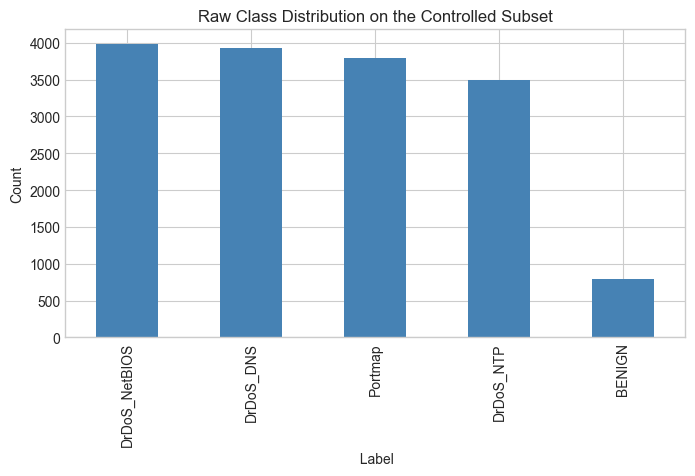

In [6]:
target_col_raw = raw_summary['target_column']
src_col_raw = [c for c in raw_df.columns if c.strip().lower() == 'source ip'][0]
schema_df = pd.DataFrame({'column': raw_df.columns, 'dtype': raw_df.dtypes.astype(str).values, 'missing': raw_df.isna().sum().values})
display(schema_df.head(20))
print('Duplicate rows in raw subset:', int(raw_df.duplicated().sum()))
print('Duplicate columns by content signature:', find_duplicate_columns(raw_df))
print('Raw source_ip availability:', raw_df[src_col_raw].notna().mean())
plt.figure(figsize=(8, 4))
raw_df[target_col_raw].astype(str).str.strip().value_counts().plot(kind='bar', color='steelblue')
plt.title('Raw Class Distribution on the Controlled Subset')
plt.ylabel('Count')
plt.show()

## Data Cleaning and Leakage-Aware Preprocessing

Cleaning follows the same principles as the main project:
- standardize column names
- convert numeric-like object fields such as `simillarhttp`
- remove duplicates and degenerate columns
- handle missing and infinite values
- keep `source_ip` and `timestamp` only as metadata
- exclude leakage-prone identifiers from model inputs

In [7]:
clean_df, cleaning_summary = preprocess_dataframe(raw_df)
target_column = cleaning_summary['target_column']
feature_columns = select_feature_columns(clean_df, target_column)
print('Cleaned shape:', cleaning_summary['final_shape'])
print('Target column:', target_column)
print('Number of model features:', len(feature_columns))
print('Converted columns:', cleaning_summary['converted_numeric_columns'])
print('Duplicate columns removed:', cleaning_summary['duplicate_columns_removed'])
print('Constant columns removed:', cleaning_summary['constant_columns_removed'])
print('Near-constant columns removed:', cleaning_summary['near_constant_columns_removed'])
print('Leakage-prone columns kept only as metadata if present:', cleaning_summary['candidate_leakage_columns'])
display(pd.DataFrame({'count': pd.Series(cleaning_summary['label_distribution_after_cleaning'])}))
display(pd.DataFrame({'missing_count': pd.Series(cleaning_summary['missing_values_top10'])}))

Cleaned shape: (16000, 69)
Target column: label
Number of model features: 60
Converted columns: []
Duplicate columns removed: ['fwd_urg_flags', 'bwd_urg_flags', 'fin_flag_count', 'rst_flag_count', 'psh_flag_count', 'ece_flag_count', 'fwd_header_length_1', 'fwd_avg_bytes_bulk', 'fwd_avg_packets_bulk', 'fwd_avg_bulk_rate', 'bwd_avg_bytes_bulk', 'bwd_avg_packets_bulk', 'bwd_avg_bulk_rate', 'subflow_fwd_packets', 'subflow_bwd_packets']
Constant columns removed: ['bwd_psh_flags']
Near-constant columns removed: ['syn_flag_count', 'active_std', 'idle_std', 'simillarhttp']
Leakage-prone columns kept only as metadata if present: ['unnamed_0', 'flow_id', 'source_ip', 'destination_ip', 'source_port', 'destination_port', 'timestamp']


,count
DrDoS_NetBIOS,3983
DrDoS_DNS,3935
Portmap,3798
DrDoS_NTP,3495
BENIGN,789


,missing_count
flow_packets_s,547
flow_bytes_s,547
source_ip,0
flow_id,0
unnamed_0,0
destination_ip,0
source_port,0
destination_port,0
protocol,0
total_fwd_packets,0


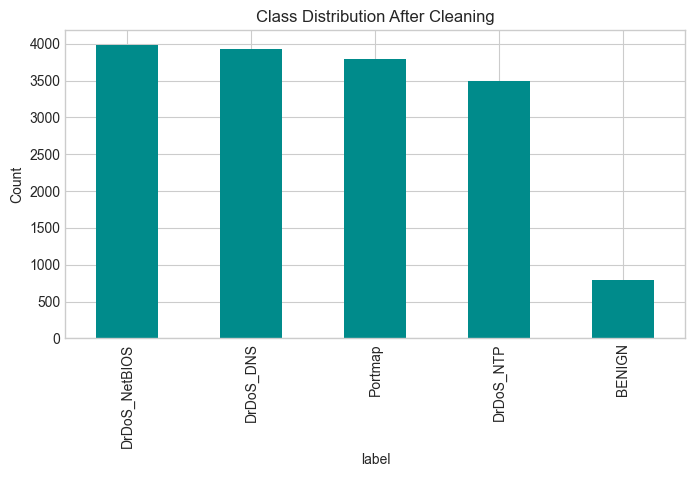

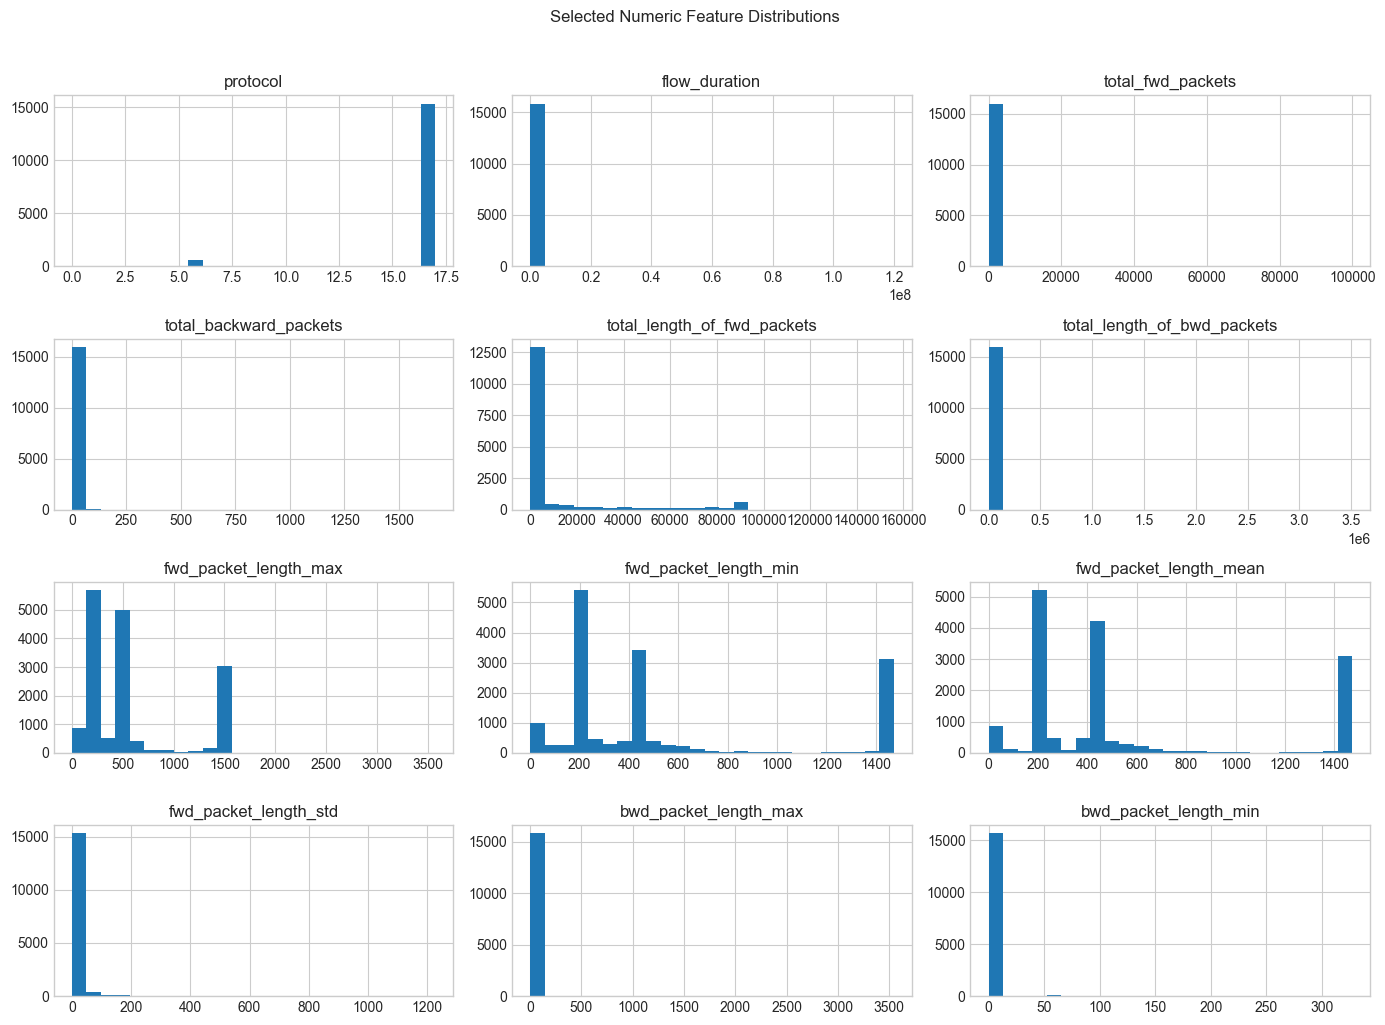

In [8]:
plt.figure(figsize=(8, 4))
clean_df[target_column].value_counts().plot(kind='bar', color='darkcyan')
plt.title('Class Distribution After Cleaning')
plt.ylabel('Count')
plt.show()

numeric_preview = feature_columns[:12]
clean_df[numeric_preview].hist(figsize=(14, 10), bins=25)
plt.suptitle('Selected Numeric Feature Distributions', y=1.02)
plt.tight_layout()
plt.show()

## Experiment A - Row-Wise Benchmark Split

This benchmark preserves class balance through a standard stratified row-wise split. It is useful for pipeline validation, but it is methodologically optimistic because rows from the same `source_ip` may still appear in both train and test.

In [9]:
row_train_df, row_test_df = stratified_rowwise_split(clean_df, target_column, test_size=0.2)
print('Row-wise train shape:', row_train_df.shape)
print('Row-wise test shape:', row_test_df.shape)
print('source_ip overlap across row-wise train/test:', len(set(row_train_df['source_ip'].dropna()) & set(row_test_df['source_ip'].dropna())))
display(pd.DataFrame({'train': row_train_df[target_column].value_counts(), 'test': row_test_df[target_column].value_counts()}).fillna(0).astype(int))

Row-wise train shape: (12800, 69)
Row-wise test shape: (3200, 69)
source_ip overlap across row-wise train/test: 19


,train,test
label,,
DrDoS_NetBIOS,3186,797
DrDoS_DNS,3148,787
Portmap,3039,759
DrDoS_NTP,2796,699
BENIGN,631,158


### Baseline Model on the Row-Wise Benchmark

A simple Logistic Regression baseline is used as a fast reference model.

Row-wise Logistic accuracy: 0.8313
Row-wise Logistic weighted F1: 0.8254
Row-wise Logistic macro F1: 0.8484


,precision,recall,f1-score,support
BENIGN,0.923077,0.987342,0.954128,158.00000
DrDoS_DNS,0.943056,0.862770,0.901128,787.00000
DrDoS_NTP,0.911480,0.942775,0.926864,699.00000
DrDoS_NetBIOS,0.873469,0.537014,0.665113,797.00000
Portmap,0.672131,0.972332,0.794830,759.00000
accuracy,0.831250,0.831250,0.831250,0.83125
macro avg,0.864643,0.860447,0.848413,3200.00000
weighted avg,0.853581,0.831250,0.825371,3200.00000


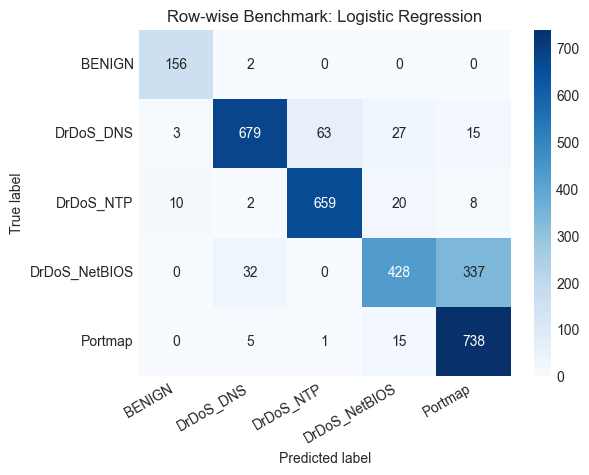

In [10]:
row_log_model, row_log_metrics, row_prepared = train_logistic(row_train_df, row_test_df, target_column, feature_columns)
row_log_report = pd.DataFrame(row_log_metrics['classification_report']).T
print('Row-wise Logistic accuracy:', round(row_log_metrics['accuracy'], 4))
print('Row-wise Logistic weighted F1:', round(row_log_metrics['f1_weighted'], 4))
print('Row-wise Logistic macro F1:', round(row_log_metrics['f1_macro'], 4))
display(row_log_report)
plot_confusion(np.array(row_log_metrics['confusion_matrix']), row_prepared['label_encoder'].classes_, 'Row-wise Benchmark: Logistic Regression')

### LSTM on the Row-Wise Benchmark

The LSTM receives short sequences constructed by grouping rows with the same `source_ip` and ordering them by `timestamp`. This adds temporal context without using identifiers as direct features.

Row-wise LSTM accuracy: 0.8772
Row-wise LSTM weighted F1: 0.8728
Row-wise LSTM macro F1: 0.8837
Epochs run: 6


,precision,recall,f1-score,support
BENIGN,0.863388,1.000000,0.926686,158.000000
DrDoS_DNS,0.994792,0.970775,0.982637,787.000000
DrDoS_NTP,0.978386,0.971388,0.974874,699.000000
DrDoS_NetBIOS,0.972399,0.574655,0.722397,797.000000
Portmap,0.690037,0.985507,0.811720,759.000000
accuracy,0.877188,0.877188,0.877188,0.877188
macro avg,0.899800,0.900465,0.883663,3200.000000
weighted avg,0.906859,0.877188,0.872823,3200.000000


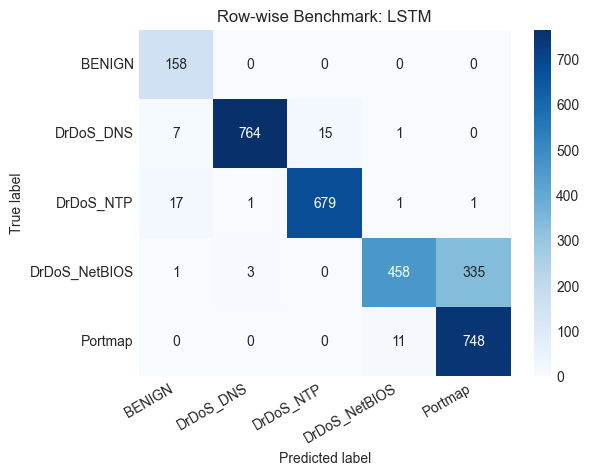

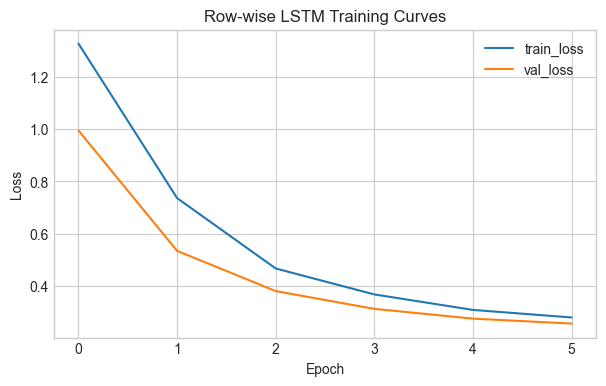

In [11]:
row_lstm_model, row_lstm_metrics, row_lstm_history, row_lstm_prepared = train_lstm(row_train_df, row_test_df, target_column, feature_columns, sequence_length=SEQUENCE_LENGTH)
row_lstm_report = pd.DataFrame(row_lstm_metrics['classification_report']).T
print('Row-wise LSTM accuracy:', round(row_lstm_metrics['accuracy'], 4))
print('Row-wise LSTM weighted F1:', round(row_lstm_metrics['f1_weighted'], 4))
print('Row-wise LSTM macro F1:', round(row_lstm_metrics['f1_macro'], 4))
print('Epochs run:', len(row_lstm_history['train_loss']))
display(row_lstm_report)
plot_confusion(np.array(row_lstm_metrics['confusion_matrix']), row_lstm_prepared['label_encoder'].classes_, 'Row-wise Benchmark: LSTM')
plt.figure(figsize=(7, 4))
plt.plot(row_lstm_history['train_loss'], label='train_loss')
plt.plot(row_lstm_history['val_loss'], label='val_loss')
plt.title('Row-wise LSTM Training Curves')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.show()

## Experiment B - Strict Group-Aware Robustness Split

This experiment uses `source_ip` as a grouping key and enforces a strict **train/test separation with zero group overlap**. It is the more honest robustness check for this dataset slice.

In [12]:
group_train_df, group_test_df, group_summary = group_aware_train_test_split(clean_df, target_column, group_column='source_ip', test_size=GROUP_TEST_SIZE)
print('Group-aware train rows:', group_summary['train_rows'])
print('Group-aware test rows:', group_summary['test_rows'])
print('Train unique source_ip:', group_summary['train_unique_groups'])
print('Test unique source_ip:', group_summary['test_unique_groups'])
print('Exact source_ip overlap:', group_summary['group_overlap'])
print('Unique source_ip per class:', group_summary['unique_groups_per_class'])
display(pd.DataFrame({'train': pd.Series(group_summary['train_class_distribution']), 'test': pd.Series(group_summary['test_class_distribution'])}).fillna(0).astype(int))

Group-aware train rows: 885
Group-aware test rows: 15115
Train unique source_ip: 96
Test unique source_ip: 1
Exact source_ip overlap: 0
Unique source_ip per class: {'BENIGN': 95, 'DrDoS_DNS': 2, 'DrDoS_NTP': 2, 'DrDoS_NetBIOS': 2, 'Portmap': 2}


,train,test
BENIGN,789,0
DrDoS_DNS,37,3898
DrDoS_NTP,36,3459
DrDoS_NetBIOS,6,3977
Portmap,17,3781


### Baseline Model Under Group-Aware Evaluation

This is the same baseline model, trained and tested under the stricter split. The goal is not to maximize accuracy, but to measure how much performance changes when group leakage is removed.

Group-aware Logistic accuracy: 0.2106
Group-aware Logistic weighted F1: 0.1954
Group-aware Logistic macro F1: 0.1515


,precision,recall,f1-score,support
BENIGN,0.000000,0.000000,0.000000,0.000000
DrDoS_DNS,0.483415,0.684197,0.566543,3898.000000
DrDoS_NTP,0.000000,0.000000,0.000000,3459.000000
DrDoS_NetBIOS,0.556522,0.064370,0.115393,3977.000000
Portmap,0.083844,0.068765,0.075559,3781.000000
accuracy,0.210586,0.210586,0.210586,0.210586
macro avg,0.224756,0.163466,0.151499,15115.000000
weighted avg,0.292071,0.210586,0.195368,15115.000000


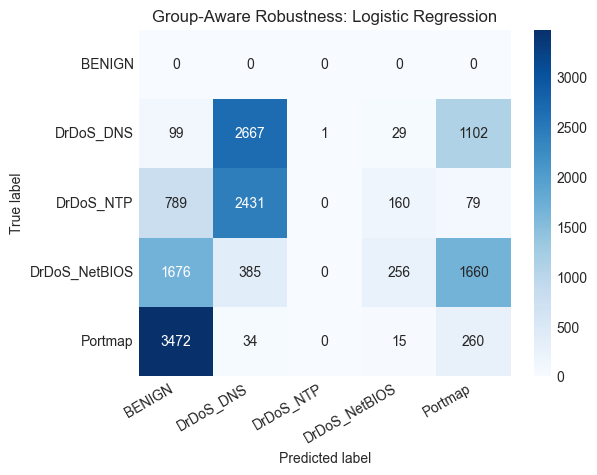

In [13]:
group_log_model, group_log_metrics, group_prepared = train_logistic(group_train_df, group_test_df, target_column, feature_columns)
group_log_report = pd.DataFrame(group_log_metrics['classification_report']).T
print('Group-aware Logistic accuracy:', round(group_log_metrics['accuracy'], 4))
print('Group-aware Logistic weighted F1:', round(group_log_metrics['f1_weighted'], 4))
print('Group-aware Logistic macro F1:', round(group_log_metrics['f1_macro'], 4))
display(group_log_report)
plot_confusion(np.array(group_log_metrics['confusion_matrix']), group_prepared['label_encoder'].classes_, 'Group-Aware Robustness: Logistic Regression')

### LSTM Under Group-Aware Evaluation

The LSTM is retrained under the same strict group-aware protocol. Sequences are built separately inside the train and test partitions so that no sequence history can cross the split boundary.

Group-aware LSTM accuracy: 0.2339
Group-aware LSTM weighted F1: 0.1085
Group-aware LSTM macro F1: 0.0842
Epochs run: 6


,precision,recall,f1-score,support
BENIGN,0.000000,0.000000,0.000000,0.000000
DrDoS_DNS,0.271936,0.905593,0.418271,3898.000000
DrDoS_NTP,1.000000,0.001446,0.002887,3459.000000
DrDoS_NetBIOS,0.000000,0.000000,0.000000,3977.000000
Portmap,0.000000,0.000000,0.000000,3781.000000
accuracy,0.233874,0.233874,0.233874,0.233874
macro avg,0.254387,0.181408,0.084232,15115.000000
weighted avg,0.298975,0.233874,0.108528,15115.000000


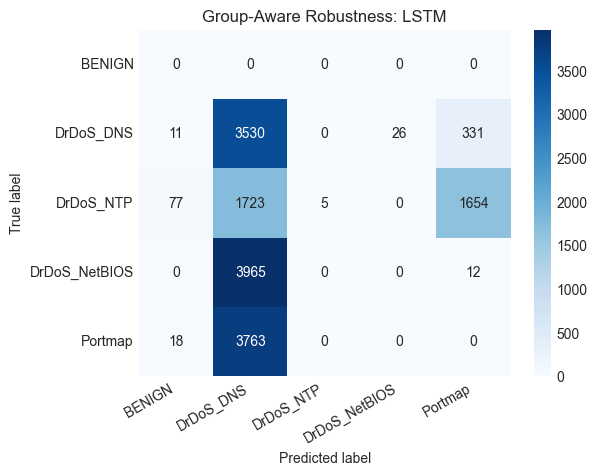

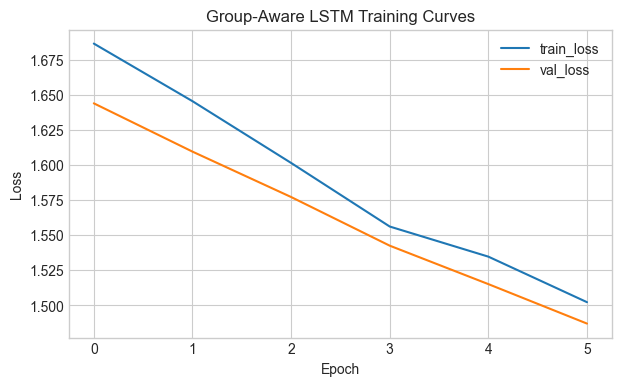

In [14]:
group_lstm_model, group_lstm_metrics, group_lstm_history, group_lstm_prepared = train_lstm(group_train_df, group_test_df, target_column, feature_columns, sequence_length=SEQUENCE_LENGTH)
group_lstm_report = pd.DataFrame(group_lstm_metrics['classification_report']).T
print('Group-aware LSTM accuracy:', round(group_lstm_metrics['accuracy'], 4))
print('Group-aware LSTM weighted F1:', round(group_lstm_metrics['f1_weighted'], 4))
print('Group-aware LSTM macro F1:', round(group_lstm_metrics['f1_macro'], 4))
print('Epochs run:', len(group_lstm_history['train_loss']))
display(group_lstm_report)
plot_confusion(np.array(group_lstm_metrics['confusion_matrix']), group_lstm_prepared['label_encoder'].classes_, 'Group-Aware Robustness: LSTM')
plt.figure(figsize=(7, 4))
plt.plot(group_lstm_history['train_loss'], label='train_loss')
plt.plot(group_lstm_history['val_loss'], label='val_loss')
plt.title('Group-Aware LSTM Training Curves')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.show()

## Lightweight Feature Ablation Under the Strict Split

A single ablation is included to test whether `inbound` behaves like a shortcut feature. This keeps the notebook practical while still checking an important robustness hypothesis.

In [15]:
feature_columns_no_inbound = [c for c in feature_columns if c != 'inbound']
_, group_log_metrics_no_inbound, _ = train_logistic(group_train_df, group_test_df, target_column, feature_columns_no_inbound)
ablation_df = pd.DataFrame([
    {'setting': 'Group-aware logistic with full features', 'accuracy': group_log_metrics['accuracy'], 'weighted_f1': group_log_metrics['f1_weighted'], 'macro_f1': group_log_metrics['f1_macro']},
    {'setting': 'Group-aware logistic without inbound', 'accuracy': group_log_metrics_no_inbound['accuracy'], 'weighted_f1': group_log_metrics_no_inbound['f1_weighted'], 'macro_f1': group_log_metrics_no_inbound['f1_macro']},
]).round(4)
display(ablation_df)

,setting,accuracy,weighted_f1,macro_f1
0,Group-aware logistic with full features,0.2106,0.1954,0.1515
1,Group-aware logistic without inbound,0.4208,0.3454,0.2706


## Final Comparison and Interpretation

The table below summarizes the benchmark and robustness experiments side by side.

In [16]:
comparison_df = pd.DataFrame([
    {'protocol': 'Row-wise benchmark', 'model': 'Logistic Regression', 'accuracy': row_log_metrics['accuracy'], 'weighted_f1': row_log_metrics['f1_weighted'], 'macro_f1': row_log_metrics['f1_macro']},
    {'protocol': 'Row-wise benchmark', 'model': 'LSTM', 'accuracy': row_lstm_metrics['accuracy'], 'weighted_f1': row_lstm_metrics['f1_weighted'], 'macro_f1': row_lstm_metrics['f1_macro']},
    {'protocol': 'Group-aware robustness', 'model': 'Logistic Regression', 'accuracy': group_log_metrics['accuracy'], 'weighted_f1': group_log_metrics['f1_weighted'], 'macro_f1': group_log_metrics['f1_macro']},
    {'protocol': 'Group-aware robustness', 'model': 'LSTM', 'accuracy': group_lstm_metrics['accuracy'], 'weighted_f1': group_lstm_metrics['f1_weighted'], 'macro_f1': group_lstm_metrics['f1_macro']},
]).round(4)
display(comparison_df)
print('Methodological reading:')
print('- Row-wise metrics are useful as a benchmark but optimistic when source_ip groups overlap.')
print('- Group-aware metrics are more realistic for robustness across unseen source_ip groups.')
print('- If removing inbound improves the strict split result, the feature behaves like a shortcut rather than a stable behavioral signal.')

,protocol,model,accuracy,weighted_f1,macro_f1
0,Row-wise benchmark,Logistic Regression,0.8312,0.8254,0.8484
1,Row-wise benchmark,LSTM,0.8772,0.8728,0.8837
2,Group-aware robustness,Logistic Regression,0.2106,0.1954,0.1515
3,Group-aware robustness,LSTM,0.2339,0.1085,0.0842


Methodological reading:
- Row-wise metrics are useful as a benchmark but optimistic when source_ip groups overlap.
- Group-aware metrics are more realistic for robustness across unseen source_ip groups.
- If removing inbound improves the strict split result, the feature behaves like a shortcut rather than a stable behavioral signal.


## Final Conclusion

This standalone notebook demonstrates a complete, executable DDoS-detection workflow on a controlled subset of CIC-DDoS2019 using only the dataset files and notebook code.

### What this notebook validates
- the data can be loaded safely with chunk-based sampling
- the cleaning and preprocessing steps can be reproduced without external project files
- the pipeline supports both a practical benchmark split and a stricter group-aware robustness split
- baseline and LSTM models can be trained and compared in one place
- a lightweight ablation can reveal whether a feature such as `inbound` behaves like a shortcut

### Recommended interpretation
- use the **row-wise benchmark** only as a pipeline reference
- use the **group-aware split** when discussing robustness and generalization
- interpret LSTM carefully because the dataset is fundamentally tabular flow data
- scale to larger data only after this notebook is validated end to end